# ResNet50 U-Net with the DEM

Same as `unet_pretrained.ipynb` (phase 1 + augmentation), but the model also gets the elevation (DEM) as a 4th input channel. ResNet's first layer gets an extra DEM input that starts at zero, so training starts from the RGB model and the DEM weights are learned. Weights are saved to `unet_dem.weights.h5`.

In [1]:
import tensorflow as tf
from tensorflow import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793675660.170478   17559 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
Keras: 3.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
MAX_UNKNOWN = 1.0 # 1.0 = keep every training tile try 0.5 to drop tiles

In [4]:
import sys
sys.path.append("../scripts")
from dataset import get_tiles, SPLITS
X_train, y_train = get_tiles(SPLITS["train"], stride=128,
                             max_unknown=MAX_UNKNOWN)

# Val and test no overlap, keep every tile (the defaults)
X_val, y_val = get_tiles(SPLITS["val"])
X_test, y_test = get_tiles(SPLITS["test"])

In [5]:
import numpy as np

for name, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    unknown = (y == -1).mean()
    known = y[y != -1]
    print(f"{name:5}  X {X.shape}  y {y.shape}  unknown {unknown:.1%}  flood (of known) {known.mean():.1%}")

Train  X (1972, 256, 256, 4)  y (1972, 256, 256)  unknown 23.7%  flood (of known) 55.7%
Val    X (110, 256, 256, 4)  y (110, 256, 256)  unknown 20.0%  flood (of known) 51.3%
Test   X (287, 256, 256, 4)  y (287, 256, 256)  unknown 48.5%  flood (of known) 76.0%


In [6]:
#make copy of the training tiles that keeps only the rgb channels and leaves out the dem part

X_train_rgb = X_train[..., :3]
X_val_rgb = X_val[..., :3]
X_test_rgb = X_test[..., :3]

print(X_train_rgb.shape, X_val_rgb.shape, X_test_rgb.shape)
print("RGB min:", X_train_rgb.min(), "max:", X_train_rgb.max())

(1972, 256, 256, 3) (110, 256, 256, 3) (287, 256, 256, 3)
RGB min: 0.0 max: 1.0


## Prepare the images for ResNet50

RGB: same as before (0-255, then `preprocess_input`).
DEM: already centered per image by `dataset.py`. Its spread is only ~1-4 m, so it is multiplied by `DEM_SCALE` to be on a similar scale to the preprocessed RGB.

In [7]:
from tensorflow.keras.applications.resnet50 import preprocess_input

DEM_SCALE = 40  # the DEM now has std 1 per image (dataset.DEM_STANDARDIZE); x40 keeps it near its old typical spread (about 2 m x 20)

def preprocess(x):
    rgb = preprocess_input(x[..., :3] * 255.0)  # 0-1 to 0-255
    return np.concatenate([rgb, x[..., 3:] * DEM_SCALE], axis=-1)

# in place, a chunk at a time: a second full copy of the training tiles froze the 16 GB PC
X_train_in = X_train
for i in range(0, len(X_train), 256):
    X_train[i:i + 256] = preprocess(X_train[i:i + 256])
X_val_in = preprocess(X_val)
X_test_in = preprocess(X_test)

print(X_train_in.shape)
print("RGB min/max:", X_train_in[..., :3].min(), X_train_in[..., :3].max())
print("DEM min/max:", X_train_in[..., 3].min(), X_train_in[..., 3].max())

(1972, 256, 256, 4)
RGB min/max: -123.68 151.061
DEM min/max: -257.75507 177.57086


## Prepare the Labels

In [8]:
def prepare_labels(y):
    return y.astype("float32")[..., None] # Changes (N, 256, 256) to (N, 256, 256, 1)

y_train_in = prepare_labels(y_train)
y_val_in = prepare_labels(y_val)
y_test_in = prepare_labels(y_test)

print(y_train_in.shape)
print("values:", np.unique(y_train_in))

(1972, 256, 256, 1)
values: [-1.  0.  1.]


## Loss function (skips unknown pixels)

In [9]:
def masked_bce(y_true, y_pred):
    known = tf.cast(y_true != -1, "float32") # 1 = labeled pixel, 0 = unknown, turns T/F into 1.0/0.0
    y_true = tf.where(y_true == -1, 0.0, y_true) # -1 would break the loss , so set iti to 0
                                                 # replaces every -1 with 0. BCE only understands labels of 0 or 1, and a -1 would give nonsense.
    loss = keras.losses.binary_crossentropy(y_true, y_pred)[..., None] #computes loss for every pixel
 
    return tf.reduce_sum(loss * known) / tf.maximum(tf.reduce_sum(known), 1.0) #average over labeled picels only
                                                              #loss * known zeros out the pentalty on unknown pixels
                                                              #tf.reduce_sum / tf.reduce_sum adds up the remaining penalties and divides by how many pixels are known.
                                                              #gives the average penallty over labeled pixels only



In [10]:
y_true = tf.constant([[[[-1.0], [1.0]], [[0.0], [1.0]]]])   # unknown, flood, dry, flood
y_pred = tf.constant([[[[0.9], [0.9]], [[0.1], [0.8]]]])    # model's guesses
print(masked_bce(y_true, y_pred).numpy())

I0000 00:00:1793675687.414072   17559 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6061 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2080, pci bus id: 0000:01:00.0, compute capability: 7.5


0.14462154


## Build the model: ResNet50 encoder
## Tutorial Repo this code came from:
https://github.com/nikhilroxtomar/Semantic-Segmentation-Architecture/blob/main/TensorFlow/resnet50_unet.py

In [ ]:
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, Conv2DTranspose, Concatenate, Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50

def conv_block(x, num_filters):
    x = Conv2D(num_filters, 3, padding="same")(x) #the 3 is how many diff patterns model looks for
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def decoder_block(x, skip_features, num_filters):
    x = Conv2DTranspose(num_filters, 2, strides=2, padding="same")(x)   # learned 2x so 16x16 goes to 32x32
    x = Concatenate()([x, skip_features])
    return conv_block(x, num_filters)

def build_resnet50_unet(input_shape):
    inputs = Input(input_shape)
    resnet50 = ResNet50(include_top=False, weights=None, input_tensor=inputs)

    # ImageNet weights only exist for 3 channels: copy them over, and give conv1 a 4th (DEM) input
    # that starts at zero, so the model starts out identical to the RGB one
    pretrained = ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    for layer, src in zip(resnet50.layers, pretrained.layers):
        weights = src.get_weights()
        if layer.name == "conv1_conv":
            kernel, bias = weights
            weights = [np.concatenate([kernel, np.zeros_like(kernel[:, :, :1])], axis=2), bias]
        layer.set_weights(weights)

    # Encoder skips (sizes for 256 x 256 tiles)
    s1 = inputs                                          # 256 
    s2 = resnet50.get_layer("conv1_relu").output         # 128
    s3 = resnet50.get_layer("conv2_block3_out").output   # 64
    s4 = resnet50.get_layer("conv3_block4_out").output   # 32

    # Bridge
    b1 = resnet50.get_layer("conv4_block6_out").output   # 16

    # Decoder
    d1 = decoder_block(b1, s4, 512)   # 32
    d2 = decoder_block(d1, s3, 256)   # 64
    d3 = decoder_block(d2, s2, 128)   # 128
    d4 = decoder_block(d3, s1, 64)    # 256

    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)
    return Model(inputs, outputs, name="ResNet50_U-Net"), resnet50

model, encoder = build_resnet50_unet((256, 256, 4))
print(model.input_shape, "->", model.output_shape)

(None, 256, 256, 4) -> (None, 256, 256, 1)


In [ ]:
from pathlib import Path

#freeze encoder
encoder.trainable = False
encoder.get_layer("conv1_conv").trainable = True  # the only encoder layer that can learn from the DEM

model.compile(
    optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),  # clipnorm: one bad batch cannot blow up the weights
    loss=masked_bce,
    jit_compile=False,  # XLA's compiled step needs more than the 2080's 8 GB
)

#save best weights
Path("../outputs").mkdir(exist_ok=True)
checkpoint = keras.callbacks.ModelCheckpoint(
    "../outputs/unet_dem.weights.h5",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
)

MEAN_BGR = tf.constant([103.939, 116.779, 123.68])  # what preprocess_input subtracted (blue, green, red)

def augment(x, y):

    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    x, y = tf.image.rot90(x, k), tf.image.rot90(y, k)
    if tf.random.uniform([]) < 0.5:
        x, y = tf.image.flip_left_right(x), tf.image.flip_left_right(y)

    # Random brightness and contrast on the photo only (not the DEM), so the model does not depend on exposure.
    # The held-out Ida imagery is about 30% darker than Harvey and the model missed nearly all of its flood.
    rgb = x[..., :3] + MEAN_BGR  # undo preprocess_input: back to 0-255
    rgb = rgb * tf.random.uniform([], 0.6, 1.4)
    mean = tf.reduce_mean(rgb)
    rgb = (rgb - mean) * tf.random.uniform([], 0.8, 1.2) + mean
    x = tf.concat([tf.clip_by_value(rgb, 0.0, 255.0) - MEAN_BGR, x[..., 3:]], axis=-1)
    return x, y

# keep the full arrays in RAM; only each batch gets copied to the GPU
with tf.device("/CPU:0"):
    def train_tiles():  # reads tiles straight from the numpy arrays; from_tensor_slices would copy them all
        for i in np.random.permutation(len(X_train_in)):
            yield X_train_in[i], y_train_in[i]

    train_ds = (tf.data.Dataset.from_generator(train_tiles, output_signature=(
                    tf.TensorSpec((256, 256, 4), tf.float32), tf.TensorSpec((256, 256, 1), tf.float32)))
                .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(4).prefetch(2))
    val_ds = tf.data.Dataset.from_tensor_slices((X_val_in, y_val_in)).batch(4)

#trian
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[checkpoint],
)

W0000 00:00:1793675710.703326   17559 cpu_allocator_impl.cc:82] Allocation of 2067791872 exceeds 10% of free system memory.
W0000 00:00:1793675753.329756   17559 cpu_allocator_impl.cc:82] Allocation of 516947968 exceeds 10% of free system memory.


Epoch 1/15


/home/lucas/flood/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1793675762.108162   17559 cpu_allocator_impl.cc:82] Allocation of 2067791872 exceeds 10% of free system memory.
W0000 00:00:1793675765.256840   17559 cpu_allocator_impl.cc:82] Allocation of 516947968 exceeds 10% of free system memory.
I0000 00:00:1793675783.667920   17691 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1793675784.455228   17691 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugstr   
batch: 4
in_depths: 128
out_depths: 128
in: 32
in: 32
data_format: 1
filter: 3
filter: 3
filter: 128
dilation: 1
dilation: 1
stride: 1
stride: 1
padding: 

493/493 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - loss: 0.3824

W0000 00:00:1793675884.199712   17693 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugstr   
batch: 2
in_depths: 512
out_depths: 256
in: 64
in: 64
data_format: 1
filter: 3
filter: 3
filter: 512
dilation: 1
dilation: 1
stride: 1
stride: 1
padding: 1
padding: 1
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_7.5 with 8.6GB RAM, 46 cores, 1710000KHz clock, 7000000KHz mem clock, 4194304B L2$"
version: 3

W0000 00:00:1793675884.239146   17693 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: goo.gle/debugstr   
batch: 2
in_depths: 256
out_depths: 256
in: 64
in: 64
data_format: 1
filter: 3
filter: 3
filter: 256
dilation: 1
dilation: 1
stride: 1
stride: 1
padding: 1
padding: 1
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_7.5 with 8.6GB RAM, 46 cores, 1710000KHz clock, 7000000KHz mem clock, 4194304B L2$"
version: 3



493/493 ━━━━━━━━━━━━━━━━━━━━ 124s 196ms/step - loss: 0.3824 - val_loss: 1.5447
Epoch 2/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 95s 192ms/step - loss: 0.3664 - val_loss: 0.5047
Epoch 3/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 93s 189ms/step - loss: 0.3326 - val_loss: 0.3313
Epoch 4/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 95s 193ms/step - loss: 0.3025 - val_loss: 0.3185
Epoch 5/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 94s 191ms/step - loss: 0.2878 - val_loss: 0.5050
Epoch 6/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 94s 190ms/step - loss: 0.2680 - val_loss: 0.3261
Epoch 7/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 92s 186ms/step - loss: 0.2485 - val_loss: 0.3874
Epoch 8/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 95s 193ms/step - loss: 0.2327 - val_loss: 0.2942
Epoch 9/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 95s 193ms/step - loss: 0.2206 - val_loss: 0.1819
Epoch 10/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 94s 191ms/step - loss: 0.2107 - val_loss: 0.2950
Epoch 11/15
493/493 ━━━━━━━━━━━━━━━━━━━━ 92s 187ms/step - loss: 0.1982 - val_loss: 0.2552
Epoch 12/15
493/493 ━━━━━━━━━

In [13]:
#load best weights
model.load_weights("../outputs/unet_dem.weights.h5")

probs = model.predict(X_val_in, batch_size=8)[..., 0] #check against y_val

pred_flood = probs > 0.5

known = y_val != -1 #known if not -1 ehich is unknown

true_flood = y_val == 1 #whats actually water
true_dry = y_val == 0 #whats actually dry
pred_dry = ~pred_flood # everywhere the model got the opposite of flood

flood_inter = np.sum(pred_flood & true_flood & known)
flood_union = np.sum((pred_flood | true_flood) & known)
iou_flood = flood_inter / flood_union

dry_inter = np.sum(pred_dry & true_dry & known)
dry_union = np.sum((pred_dry | true_dry) & known)
iou_dry = dry_inter / dry_union

print(f"flood IoU:  {iou_flood:.3f}")
print(f"dry IoU:    {iou_dry:.3f}")

print(f"model says flood: {pred_flood[known].mean():.1%}   label says flood: {true_flood[known].mean():.1%}")



14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 427ms/step
flood IoU:  0.884
dry IoU:    0.887
model says flood: 47.0%   label says flood: 51.3%


In [19]:
for cut in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pf = probs > cut
    f = np.sum(pf & true_flood & known) / np.sum((pf | true_flood) & known)
    d = np.sum(~pf & true_dry & known) / np.sum((~pf | true_dry) & known)
    print(f"cutoff {cut}: flood IoU {f:.3f}  dry IoU {d:.3f}  says flood {pf[known].mean():.1%}")

cutoff 0.3: flood IoU 0.895  dry IoU 0.887  says flood 52.5%
cutoff 0.4: flood IoU 0.898  dry IoU 0.897  says flood 49.3%
cutoff 0.5: flood IoU 0.884  dry IoU 0.887  says flood 47.0%
cutoff 0.6: flood IoU 0.860  dry IoU 0.869  says flood 45.1%
cutoff 0.7: flood IoU 0.822  dry IoU 0.840  says flood 42.8%


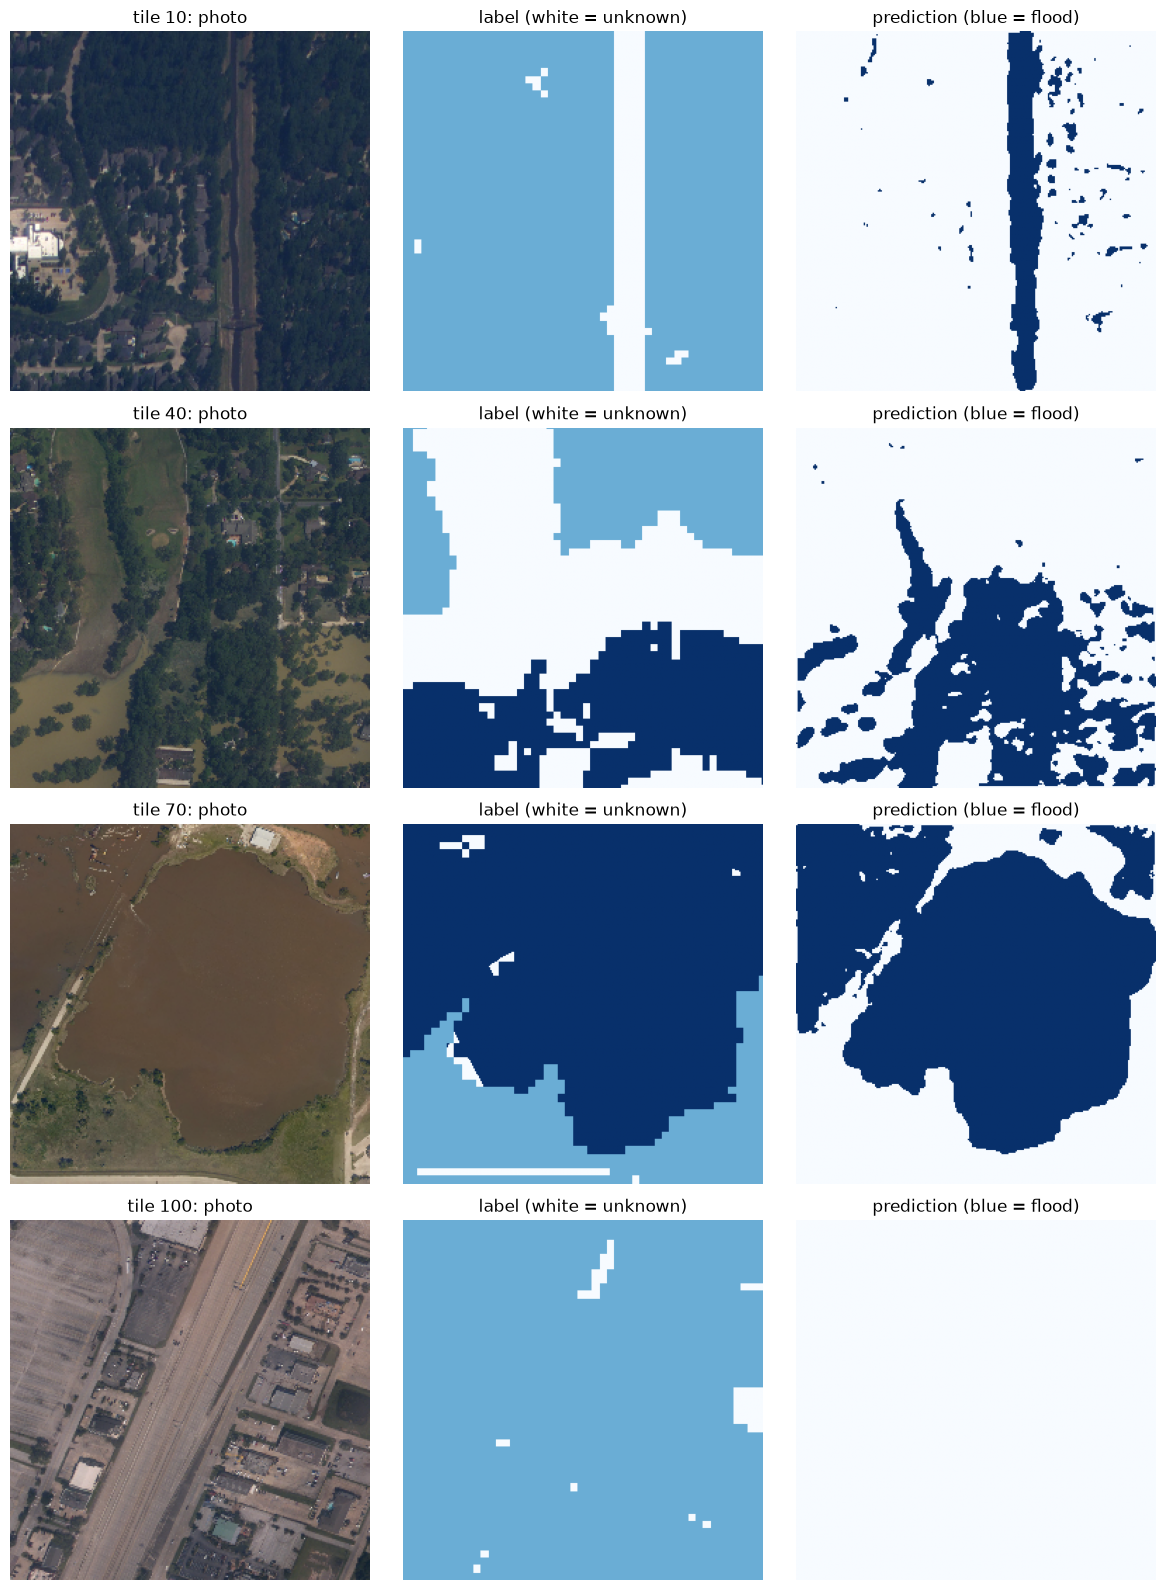

In [15]:
import matplotlib.pyplot as plt

tiles = [10, 40, 70, 100]   # 4 tiles from image 12 to look at

fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_val_rgb[t])                          # the photo
    axes[row, 1].imshow(y_val[t], cmap="Blues", vmin=-1, vmax=1)  # answer
    axes[row, 2].imshow(pred_flood[t], cmap="Blues")           # model's guess
    axes[row, 0].set_title(f"tile {t}: photo")
    axes[row, 1].set_title("label (white = unknown)")
    axes[row, 2].set_title("prediction (blue = flood)")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
CUTOFF = 0.4


model.load_weights("../outputs/unet_dem.weights.h5")

#predict on test
test_probs = model.predict(X_test_in, batch_size=8)[..., 0]


test_pred_flood = test_probs > CUTOFF
test_pred_dry = ~test_pred_flood


test_known = y_test != -1
test_true_flood = y_test == 1
test_true_dry = y_test == 0

test_iou_flood = np.sum(test_pred_flood & test_true_flood & test_known) / np.sum((test_pred_flood | test_true_flood) & test_known)
test_iou_dry = np.sum(test_pred_dry & test_true_dry & test_known) / np.sum((test_pred_dry | test_true_dry) & test_known)

print(f"TEST (cutoff {CUTOFF})")
print(f"flood IoU: {test_iou_flood:.3f}")
print(f"dry IoU:   {test_iou_dry:.3f}")
print(f"model says flood: {test_pred_flood[test_known].mean():.1%}   label says flood: {test_true_flood[test_known].mean():.1%}")

36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step
TEST (cutoff 0.4)
flood IoU: 0.649
dry IoU:   0.406
model says flood: 57.1%   label says flood: 76.0%


In [21]:
for i in SPLITS["test"]:
    Xi, yi = get_tiles([i])
    pi = model.predict(preprocess(Xi), batch_size=8, verbose=0)[..., 0] > CUTOFF
    k, tf_, td = yi != -1, yi == 1, yi == 0
    f = np.sum(pi & tf_ & k) / np.sum((pi | tf_) & k)
    d = np.sum(~pi & td & k) / np.sum((~pi | td) & k)
    print(f"image {i}: flood IoU {f:.3f}  dry IoU {d:.3f}  says flood {pi[k].mean():.1%}  label {tf_[k].mean():.1%}")

image 4: flood IoU 0.700  dry IoU 0.074  says flood 68.3%  label 97.6%
image 5: flood IoU 0.815  dry IoU 0.030  says flood 81.0%  label 99.4%
image 6: flood IoU 0.400  dry IoU 0.000  says flood 40.0%  label 100.0%
image 7: flood IoU 0.654  dry IoU 0.706  says flood 53.3%  label 37.0%
image 10: flood IoU 0.786  dry IoU 0.705  says flood 54.1%  label 64.1%
image 11: flood IoU 0.748  dry IoU 0.372  says flood 66.2%  label 85.8%


In [ ]:
# Held-out hard case: Hurricane Ida. The model never trained on this storm, and it is not used to pick the cutoff.
# Flood IoU only: this image has too few dry labels for a dry score to mean much.
for i in SPLITS["ida_hard_case"]:
    Xi, yi = get_tiles([i])
    pi = model.predict(preprocess(Xi), batch_size=8, verbose=0)[..., 0] > CUTOFF
    k, tf_ = yi != -1, yi == 1
    f = np.sum(pi & tf_ & k) / np.sum((pi | tf_) & k)
    print(f"IDA image {i}: flood IoU {f:.3f}  says flood {pi[k].mean():.1%}  label {tf_[k].mean():.1%}")


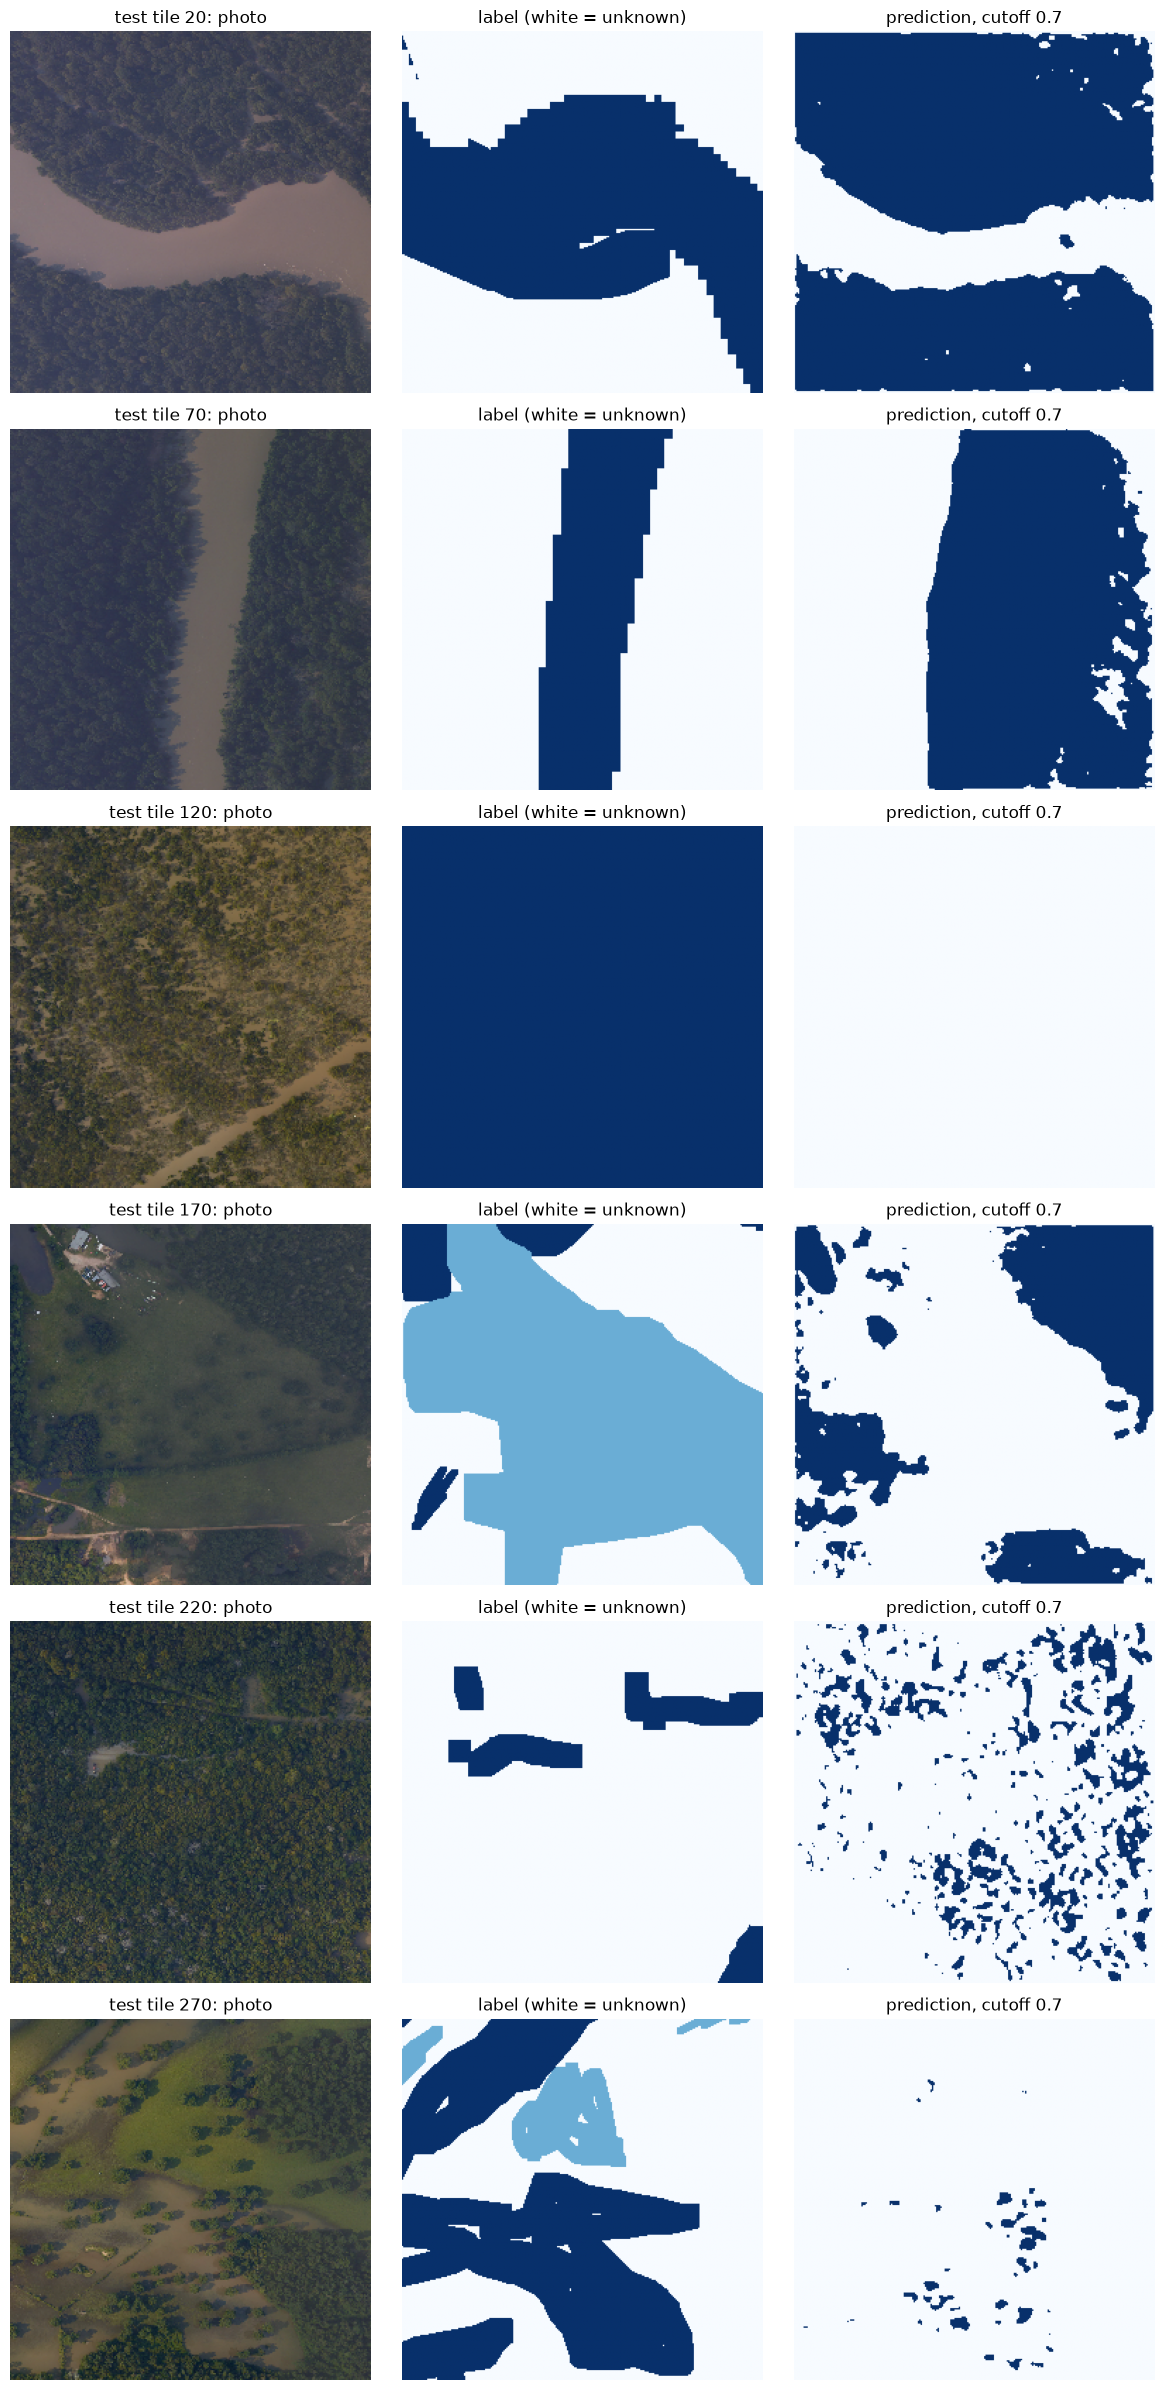

In [18]:
tiles = [20, 70, 120, 170, 220, 270]   
fig, axes = plt.subplots(len(tiles), 3, figsize=(12, 4 * len(tiles)))
for row, t in enumerate(tiles):
    axes[row, 0].imshow(X_test_rgb[t])                             
    axes[row, 1].imshow(y_test[t], cmap="Blues", vmin=-1, vmax=1)  
    axes[row, 2].imshow(test_pred_flood[t], cmap="Blues")          
    axes[row, 0].set_title(f"test tile {t}: photo")
    axes[row, 1].set_title("label (white = unknown)")
    axes[row, 2].set_title(f"prediction, cutoff {CUTOFF}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()